# Partie 1 — Compréhension métier et collecte des données

**Projet :** prédiction du churn client (Machine Learning, groupe de 5)
**Responsable :** Massamba Fall Séne (Membre 1)
**Dataset :** Telco Customer Churn (IBM Sample Data, Kaggle), fichier `data/raw/telco_customer_churn.csv`

Ce notebook présente le problème, charge les données brutes, décrit chaque variable et vérifie leur qualité.
Il **ne modifie pas** le fichier de `data/raw/` : toutes les vérifications se font en mémoire.

Sommaire :
1. Le problème du churn et l'objectif
2. Chargement du dataset
3. Dimensions, types et aperçu
4. Dictionnaire des variables
5. Répartition de la variable cible `Churn`
6. Qualité des données
7. Conclusion et points de vigilance pour les membres 2 à 5

## 1. Le problème du churn et l'objectif

Le **churn** (ou attrition) désigne le départ d'un client qui résilie son abonnement. Pour un opérateur télécom,
acquérir un nouveau client coûte beaucoup plus cher que garder un client existant. Repérer à l'avance les clients
à risque permet de lancer des actions ciblées : offre commerciale, appel de fidélisation, proposition d'un contrat plus long.

**Objectif du projet :** construire un modèle de **classification binaire supervisée** qui prédit si un client
va partir (`Churn = Yes`) ou rester (`Churn = No`), puis identifier les facteurs qui influencent le plus ce départ.

- **Variable cible :** `Churn` (Yes / No)
- **Unité d'observation :** un client par ligne
- **Métriques clés :** Recall et F1-score sur la classe « churn » (rater un client qui part coûte plus cher qu'une action
  de fidélisation inutile), complétés par la ROC-AUC. L'accuracy seule est trompeuse si les classes sont déséquilibrées.

## 2. Chargement du dataset

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Racine du projet : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine
RACINE = Path.cwd() if (Path.cwd() / "data" / "raw").exists() else Path.cwd().parent
CHEMIN_DONNEES = RACINE / "data" / "raw" / "telco_customer_churn.csv"
DOSSIER_FIGURES = RACINE / "reports" / "figures"
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CHEMIN_DONNEES)
print(f"Fichier chargé : {CHEMIN_DONNEES.relative_to(RACINE)}")

Fichier chargé : data/raw/telco_customer_churn.csv


## 3. Dimensions, types et aperçu

In [2]:
n_lignes, n_colonnes = df.shape
print(f"Nombre de lignes (clients) : {n_lignes}")
print(f"Nombre de colonnes         : {n_colonnes}")

Nombre de lignes (clients) : 7043
Nombre de colonnes         : 21


In [3]:
# Types détectés par pandas
df.dtypes.to_frame("type_pandas")

,type_pandas
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Statistiques descriptives des colonnes numériques (telles que lues par pandas)
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**Remarque :** seules `SeniorCitizen`, `tenure` et `MonthlyCharges` sont numériques. `TotalCharges` devrait l'être aussi
mais pandas la lit comme du texte (`object` avec pandas 2, `str` avec pandas 3) : on vérifie pourquoi dans la section 6.

## 4. Dictionnaire des variables

In [6]:
descriptions = {
    "customerID":       ("Identifiant",   "Identifiant unique du client (à exclure du modèle)"),
    "gender":           ("Catégorielle",  "Genre du client (Male / Female)"),
    "SeniorCitizen":    ("Binaire 0/1",   "Client senior (1) ou non (0)"),
    "Partner":          ("Catégorielle",  "Vit en couple (Yes / No)"),
    "Dependents":       ("Catégorielle",  "A des personnes à charge (Yes / No)"),
    "tenure":           ("Numérique",     "Ancienneté : nombre de mois depuis la souscription"),
    "PhoneService":     ("Catégorielle",  "Abonné au service téléphonique (Yes / No)"),
    "MultipleLines":    ("Catégorielle",  "Plusieurs lignes téléphoniques (Yes / No / No phone service)"),
    "InternetService":  ("Catégorielle",  "Type d'accès internet (DSL / Fiber optic / No)"),
    "OnlineSecurity":   ("Catégorielle",  "Option sécurité en ligne (Yes / No / No internet service)"),
    "OnlineBackup":     ("Catégorielle",  "Option sauvegarde en ligne (Yes / No / No internet service)"),
    "DeviceProtection": ("Catégorielle",  "Option protection des appareils (Yes / No / No internet service)"),
    "TechSupport":      ("Catégorielle",  "Option support technique (Yes / No / No internet service)"),
    "StreamingTV":      ("Catégorielle",  "Option streaming TV (Yes / No / No internet service)"),
    "StreamingMovies":  ("Catégorielle",  "Option streaming films (Yes / No / No internet service)"),
    "Contract":         ("Catégorielle",  "Type de contrat (Month-to-month / One year / Two year)"),
    "PaperlessBilling": ("Catégorielle",  "Facturation dématérialisée (Yes / No)"),
    "PaymentMethod":    ("Catégorielle",  "Mode de paiement (4 modalités)"),
    "MonthlyCharges":   ("Numérique",     "Montant facturé chaque mois"),
    "TotalCharges":     ("Numérique",     "Montant total facturé depuis la souscription (lu comme texte)"),
    "Churn":            ("Cible",         "Le client a-t-il quitté l'entreprise ? (Yes / No)"),
}

dictionnaire = pd.DataFrame({
    "variable": df.columns,
    "type_metier": [descriptions[c][0] for c in df.columns],
    "type_pandas": df.dtypes.astype(str).values,
    "nb_valeurs_distinctes": df.nunique().values,
    "exemples": [", ".join(map(str, df[c].unique()[:3])) for c in df.columns],
    "description": [descriptions[c][1] for c in df.columns],
})
assert set(descriptions) == set(df.columns), "Le dictionnaire ne couvre pas toutes les colonnes"
dictionnaire

,variable,type_metier,type_pandas,nb_valeurs_distinctes,exemples,description
0,customerID,Identifiant,str,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK",Identifiant unique du client (à exclure du mod...
1,gender,Catégorielle,str,2,"Female, Male",Genre du client (Male / Female)
2,SeniorCitizen,Binaire 0/1,int64,2,"0, 1",Client senior (1) ou non (0)
3,Partner,Catégorielle,str,2,"Yes, No",Vit en couple (Yes / No)
4,Dependents,Catégorielle,str,2,"No, Yes",A des personnes à charge (Yes / No)
5,tenure,Numérique,int64,73,"1, 34, 2",Ancienneté : nombre de mois depuis la souscrip...
6,PhoneService,Catégorielle,str,2,"No, Yes",Abonné au service téléphonique (Yes / No)
7,MultipleLines,Catégorielle,str,3,"No phone service, No, Yes",Plusieurs lignes téléphoniques (Yes / No / No ...
8,InternetService,Catégorielle,str,3,"DSL, Fiber optic, No",Type d'accès internet (DSL / Fiber optic / No)
9,OnlineSecurity,Catégorielle,str,3,"No, Yes, No internet service",Option sécurité en ligne (Yes / No / No intern...


In [7]:
# Modalités de chaque variable catégorielle (hors identifiant et TotalCharges)
categorielles = [c for c in df.select_dtypes(exclude="number").columns if c not in ("customerID", "TotalCharges")]
for c in categorielles:
    print(f"{c:<17} -> {sorted(df[c].unique())}")

gender            -> ['Female', 'Male']
Partner           -> ['No', 'Yes']
Dependents        -> ['No', 'Yes']
PhoneService      -> ['No', 'Yes']
MultipleLines     -> ['No', 'No phone service', 'Yes']
InternetService   -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity    -> ['No', 'No internet service', 'Yes']
OnlineBackup      -> ['No', 'No internet service', 'Yes']
DeviceProtection  -> ['No', 'No internet service', 'Yes']
TechSupport       -> ['No', 'No internet service', 'Yes']
StreamingTV       -> ['No', 'No internet service', 'Yes']
StreamingMovies   -> ['No', 'No internet service', 'Yes']
Contract          -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  -> ['No', 'Yes']
PaymentMethod     -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn             -> ['No', 'Yes']


## 5. Répartition de la variable cible `Churn`

In [8]:
effectifs = df["Churn"].value_counts().reindex(["No", "Yes"])
pourcentages = (effectifs / effectifs.sum() * 100).round(2)
repartition = pd.DataFrame({"effectif": effectifs, "pourcentage (%)": pourcentages})
repartition

,effectif,pourcentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


Figure enregistrée : reports/figures/churn_repartition.png


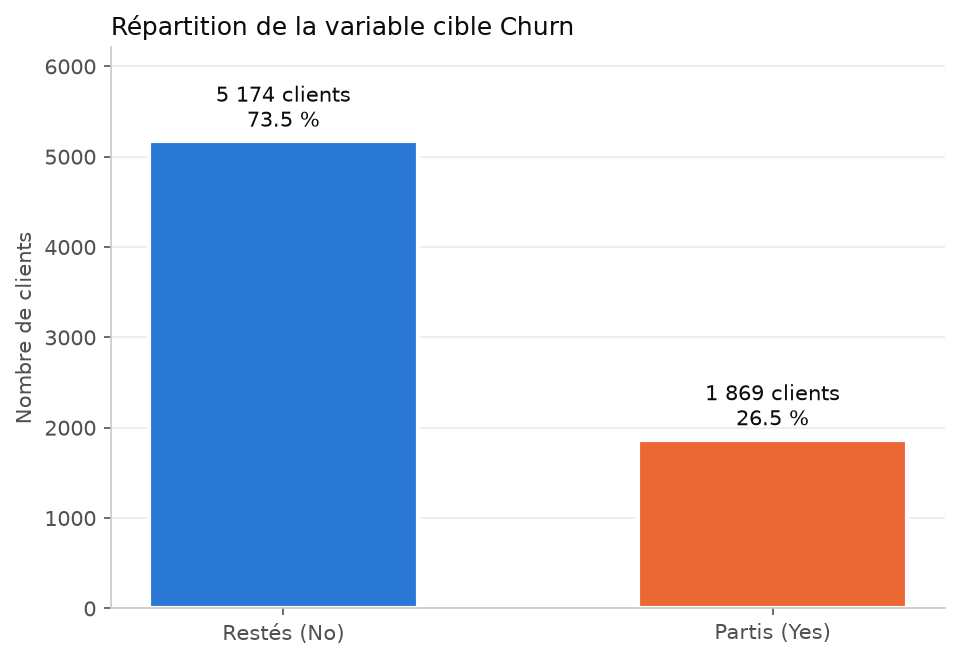

In [9]:
# Bleu = clients restés, orange = clients partis ; effectif et % écrits sur chaque barre
COULEURS = {"No": "#2a78d6", "Yes": "#eb6834"}
LIBELLES = {"No": "Restés (No)", "Yes": "Partis (Yes)"}

fig, ax = plt.subplots(figsize=(6.5, 4.5), dpi=150)
barres = ax.bar(
    [LIBELLES[k] for k in effectifs.index], effectifs.values,
    color=[COULEURS[k] for k in effectifs.index], width=0.55, edgecolor="white", linewidth=2,
)
for barre, n, p in zip(barres, effectifs.values, pourcentages.values):
    ax.text(barre.get_x() + barre.get_width() / 2, barre.get_height() + 80,
            f"{n:,} clients\n{p:.1f} %".replace(",", " "),
            ha="center", va="bottom", fontsize=10, color="#0b0b0b")

ax.set_title("Répartition de la variable cible Churn", loc="left", fontsize=12, color="#0b0b0b")
ax.set_ylabel("Nombre de clients", color="#52514e")
ax.set_ylim(0, effectifs.max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c9c8c2")
ax.tick_params(colors="#52514e")
ax.yaxis.grid(True, color="#ecebe7", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()

chemin_figure = DOSSIER_FIGURES / "churn_repartition.png"
fig.savefig(chemin_figure, bbox_inches="tight", facecolor="white")
print(f"Figure enregistrée : {chemin_figure.relative_to(RACINE)}")
plt.show()

In [10]:
taux_churn = pourcentages["Yes"]
print(f"Taux de churn : {taux_churn:.2f} %  ->  environ 1 client sur {100 / taux_churn:.1f} part.")
print(f"Un modèle qui prédit toujours « No » aurait déjà {100 - taux_churn:.2f} % d'accuracy : "
      "c'est pourquoi on privilégie Recall, F1 et ROC-AUC.")

Taux de churn : 26.54 %  ->  environ 1 client sur 3.8 part.
Un modèle qui prédit toujours « No » aurait déjà 73.46 % d'accuracy : c'est pourquoi on privilégie Recall, F1 et ROC-AUC.


## 6. Qualité des données

### 6.1 Doublons

In [11]:
nb_doublons_lignes = df.duplicated().sum()
nb_doublons_id = df["customerID"].duplicated().sum()
print(f"Lignes entièrement dupliquées : {nb_doublons_lignes}")
print(f"customerID dupliqués          : {nb_doublons_id}")

Lignes entièrement dupliquées : 0
customerID dupliqués          : 0


### 6.2 Valeurs manquantes (au sens de pandas)

In [12]:
manquantes = df.isna().sum()
print(f"Total de valeurs NaN détectées par pandas : {manquantes.sum()}")
manquantes[manquantes > 0]

Total de valeurs NaN détectées par pandas : 0


Series([], dtype: int64)

### 6.3 `TotalCharges` stocké en texte

pandas ne détecte aucune valeur manquante, pourtant `TotalCharges` est de type texte. On cherche les valeurs
qui ne se convertissent pas en nombre. La conversion est faite sur une **copie en mémoire** : le fichier brut n'est pas modifié.

In [13]:
print(f"Type de TotalCharges : {df['TotalCharges'].dtype}")

total_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
non_convertibles = df.loc[total_num.isna(), "TotalCharges"]
print(f"Valeurs non convertibles en nombre : {len(non_convertibles)}")
print(f"Valeurs brutes concernées          : {sorted(map(repr, non_convertibles.unique()))}")
print(f"Sont-elles vides après strip() ?   : {non_convertibles.str.strip().eq('').all()}")

Type de TotalCharges : str
Valeurs non convertibles en nombre : 11
Valeurs brutes concernées          : ["' '"]
Sont-elles vides après strip() ?   : True


In [14]:
# Qui sont ces clients ?
lignes_vides = df.loc[total_num.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]
print(f"tenure de ces clients : {sorted(lignes_vides['tenure'].unique().tolist())}")
print(f"Nombre total de clients avec tenure = 0 : {(df['tenure'] == 0).sum()}")
lignes_vides

tenure de ces clients : [0]
Nombre total de clients avec tenure = 0 : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [15]:
# Cohérence : pour les autres clients, TotalCharges ≈ tenure × MonthlyCharges ?
masque = total_num.notna()
ecart_relatif = (total_num[masque] - df.loc[masque, "tenure"] * df.loc[masque, "MonthlyCharges"]).abs() / total_num[masque]
print(f"Écart relatif médian entre TotalCharges et tenure × MonthlyCharges : {ecart_relatif.median():.1%}")

Écart relatif médian entre TotalCharges et tenure × MonthlyCharges : 2.0%


### 6.4 Modalités « No internet service » / « No phone service »

In [16]:
dependantes_internet = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
sans_internet = (df["InternetService"] == "No").sum()
print(f"Clients sans internet : {sans_internet}")
for c in dependantes_internet:
    print(f"  {c:<17} 'No internet service' : {(df[c] == 'No internet service').sum()}")
print(f"Clients sans téléphone : {(df['PhoneService'] == 'No').sum()}  |  "
      f"MultipleLines = 'No phone service' : {(df['MultipleLines'] == 'No phone service').sum()}")

Clients sans internet : 1526
  OnlineSecurity    'No internet service' : 1526
  OnlineBackup      'No internet service' : 1526
  DeviceProtection  'No internet service' : 1526
  TechSupport       'No internet service' : 1526
  StreamingTV       'No internet service' : 1526
  StreamingMovies   'No internet service' : 1526
Clients sans téléphone : 682  |  MultipleLines = 'No phone service' : 682


### 6.5 Vérification : le fichier brut n'a pas été modifié

In [17]:
df_relu = pd.read_csv(CHEMIN_DONNEES)
assert df_relu.equals(df), "Le DataFrame a été modifié en mémoire"
print("OK : les données en mémoire sont identiques au fichier brut, aucune écriture dans data/raw/.")

OK : les données en mémoire sont identiques au fichier brut, aucune écriture dans data/raw/.


## 7. Conclusion et points de vigilance pour les membres 2 à 5

**Bilan :** le dataset Telco Customer Churn contient **7 043 clients** et **21 colonnes** (1 identifiant, 19 variables
explicatives, 1 cible). Il n'y a **aucun doublon** et pandas ne détecte **aucun NaN**, mais une anomalie de type est
présente sur `TotalCharges`. Le taux de churn est d'environ **26,5 %** (1 869 clients partis contre 5 174 restés).

**Points de vigilance :**

| # | Point | Concerne |
|---|---|---|
| 1 | `TotalCharges` est lu en texte : **11 valeurs** sont une chaîne contenant un espace (`' '`). Elles correspondent toutes aux 11 clients avec `tenure = 0` (nouveaux clients pas encore facturés). Convertir avec `pd.to_numeric(..., errors="coerce")`, puis imputer (0 est cohérent métier) ou supprimer ces 11 lignes, en justifiant le choix. | Membres 2 et 3 |
| 2 | `customerID` est un identifiant : ne jamais l'utiliser comme variable explicative. | Membres 3 et 4 |
| 3 | Classes **déséquilibrées** (~26,5 % / 73,5 %) : stratifier le découpage train/test, envisager `class_weight` ou un rééchantillonnage (SMOTE avec `imbalanced-learn`, **uniquement sur le train**). | Membres 3 et 4 |
| 4 | Ne pas juger un modèle sur l'accuracy : un modèle naïf « toujours No » atteint déjà ~73,5 %. Utiliser Recall, F1 et ROC-AUC sur la classe churn. | Membres 4 et 5 |
| 5 | Six variables de services ont la modalité `No internet service` (1 526 clients) et `MultipleLines` a `No phone service` (682 clients) : information redondante avec `InternetService` / `PhoneService`, à encoder avec soin (fusion avec `No` ou encodage one-hot). | Membres 2 et 3 |
| 6 | `SeniorCitizen` est codée 0/1 alors que les autres binaires sont Yes/No : harmoniser l'encodage. | Membre 3 |
| 7 | `TotalCharges` ≈ `tenure` × `MonthlyCharges` : variables fortement corrélées, attention à la multicolinéarité pour les modèles linéaires. | Membres 2, 3 et 4 |
| 8 | `requirements.txt` ne fixe pas les versions : ce notebook a été exécuté avec pandas 3, qui lit le texte en `str` au lieu de `object`. Sélectionner les colonnes texte avec `select_dtypes(exclude="number")` plutôt qu'en testant `== "object"`. | Tous |
| 9 | Ne jamais modifier `data/raw/` : écrire les données préparées dans `data/processed/`. | Tous |